# Kepler exoplanet vetting: tabular MLP baseline (10/09/2026)

Classify Kepler KOIs as **planet** (CONFIRMED + CANDIDATE = 1) vs **false positive** (0) from physical/transit parameters.

All preprocessing lives in `src/VettingSetup.jl` so every notebook and sweep uses the same pipeline:
- leakage guard (robovetter `fpflag`s, `koi_pdisposition`, `koi_score`, `kepler_name`, vetting comments can never be inputs)
- drop rows missing **any** model feature
- split **grouped by star** (`kepid`) and stratified by system type, 80/10/10
- `log10(x + eps)` on period/depth/prad, z-score fit on the **training split only**
- MLP outputs a logit; weighted logit-BCE (stable); early stopping on validation loss

Features: period, duration, depth, impact, model SNR, prad, teq, steff, srad, slogg, `koi_count` (multiplicity). `koi_insol` dropped for now (redundant with `koi_teq`).

In [1]:
# Environment, packages, and all pipeline functions
include(joinpath(@__DIR__, "..", "src", "VettingSetup.jl"))

VettingSetup loaded: 11 features, data at c:\JuliaProjects\Exoplanet vetting\data\koi_cumulative.csv


In [2]:
# Load the cached KOI table (downloads to data/ only if missing) and clean it
df_raw = load_koi()
println("Raw table: ", size(df_raw))
println("Disposition counts: ", countmap(df_raw.koi_disposition))

df = clean_koi(df_raw)
println("Clean counts: ", countmap(df.koi_disposition))

Raw table: (9564, 153)
Disposition counts: Dict{DataStrings.DataString, Int64}("CANDIDATE" => 1977, "CONFIRMED" => 2748, "FALSE POSITIVE" => 4839)
Clean counts: Dict{DataStrings.DataString, Int64}("CANDIDATE" => 1873, "CONFIRMED" => 2746, "FALSE POSITIVE" => 4582)


┌ Info: clean_koi
│   raw = 9564
│   kept = 9201
│   stars = 7927
│   planets = 4619
│   false_pos = 4582
└ @ Main c:\JuliaProjects\Exoplanet vetting\src\VettingSetup.jl:96


In [3]:
# 80/10/10 split grouped by star: no kepid appears in more than one split
train_df, val_df, test_df = split_by_star(df; seed = 42)
describe_splits(train_df, val_df, test_df)

train   7356 KOIs   6342 stars  planet frac 0.502
val      932 KOIs    793 stars  planet frac 0.502
test     913 KOIs    792 stars  planet frac 0.499


In [4]:
# Feature matrices [n_features, n_obs]; scaler fit on train only
data = prepare_data(train_df, val_df, test_df)
println("Xtr ", size(data.Xtr), "  Xva ", size(data.Xva), "  Xte ", size(data.Xte))

# Sanity check one mini-batch
xb, yb = first(make_loader(data.Xtr, data.ytr; batchsize = 128))
println("batch: ", size(xb), " ", typeof(yb), " length ", length(yb))

# Class balance is ~1:1, so the neutral weight is ~1; raise pos_weight to favor recall on planets
pos_weight = sum(data.ytr .== 0) / sum(data.ytr .== 1)
println("neg/pos ratio in train: ", round(pos_weight; digits = 3))

Xtr (11, 7356)  Xva (11, 932)  Xte (11, 913)
batch: (11, 128) Vector{Float32} length 128
neg/pos ratio in train: 0.991


epoch   20  train 0.3507  val 0.3692
epoch   40  train 0.3327  val 0.3587
epoch   60  train 0.3243  val 0.3468
epoch   80  train 0.3173  val 0.3434
epoch  100  train 0.3119  val 0.3425


┌ Info: Early stop
│   epoch = 109
│   best_epoch = 84
└ @ Main c:\JuliaProjects\Exoplanet vetting\src\VettingSetup.jl:222


best epoch: 84


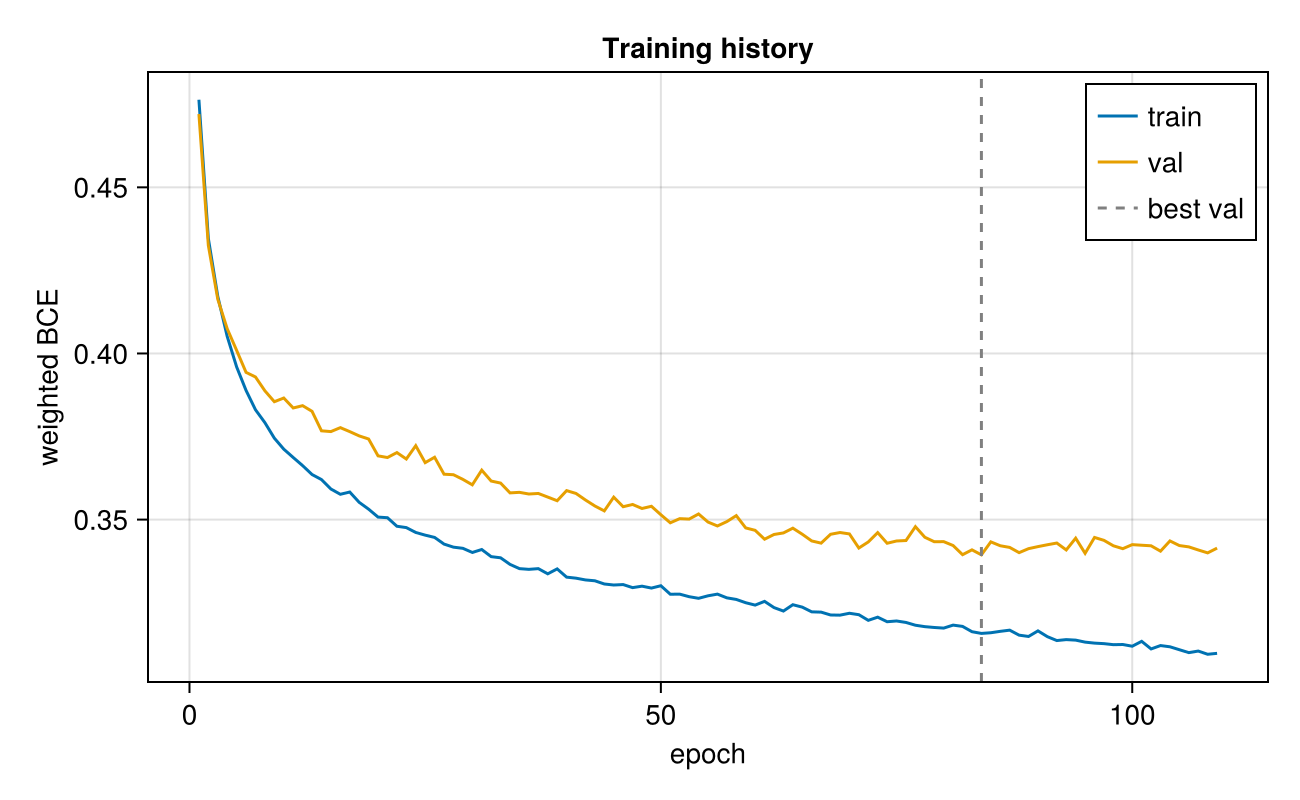

In [5]:
# Train: Dense(11=>64, relu) -> Dropout(0.2) -> Dense(64=>32, relu) -> Dense(32=>1) logit
# Up to 200 epochs with early stopping (patience 25); about a minute including compilation
model, hist = train_model(data; epochs = 200, lr = 1e-3, batchsize = 128,
                          pos_weight = pos_weight, patience = 25, seed = 1)
println("best epoch: ", hist.best_epoch)
fig_hist = plot_history(hist)
savefig("exo100926_history.png", fig_hist)
fig_hist

In [6]:
# Validation metrics: all labels, and CONFIRMED vs FP only (drops noisier CANDIDATE labels)
p_val = predict_proba(model, data.Xva)
evaluate_subsets(val_df, p_val)

Row,subset,n,roc_auc,pr_auc,accuracy,precision,recall,f1,tp,fp,tn,fn
,String,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Int64,Int64,Int64,Int64
1,all (CONF+CAND vs FP),932,0.928179,0.919941,0.847639,0.836777,0.865385,0.85084,405,79,385,63
2,CONFIRMED vs FP,757,0.961545,0.928825,0.878468,0.779944,0.955631,0.858896,280,79,385,13


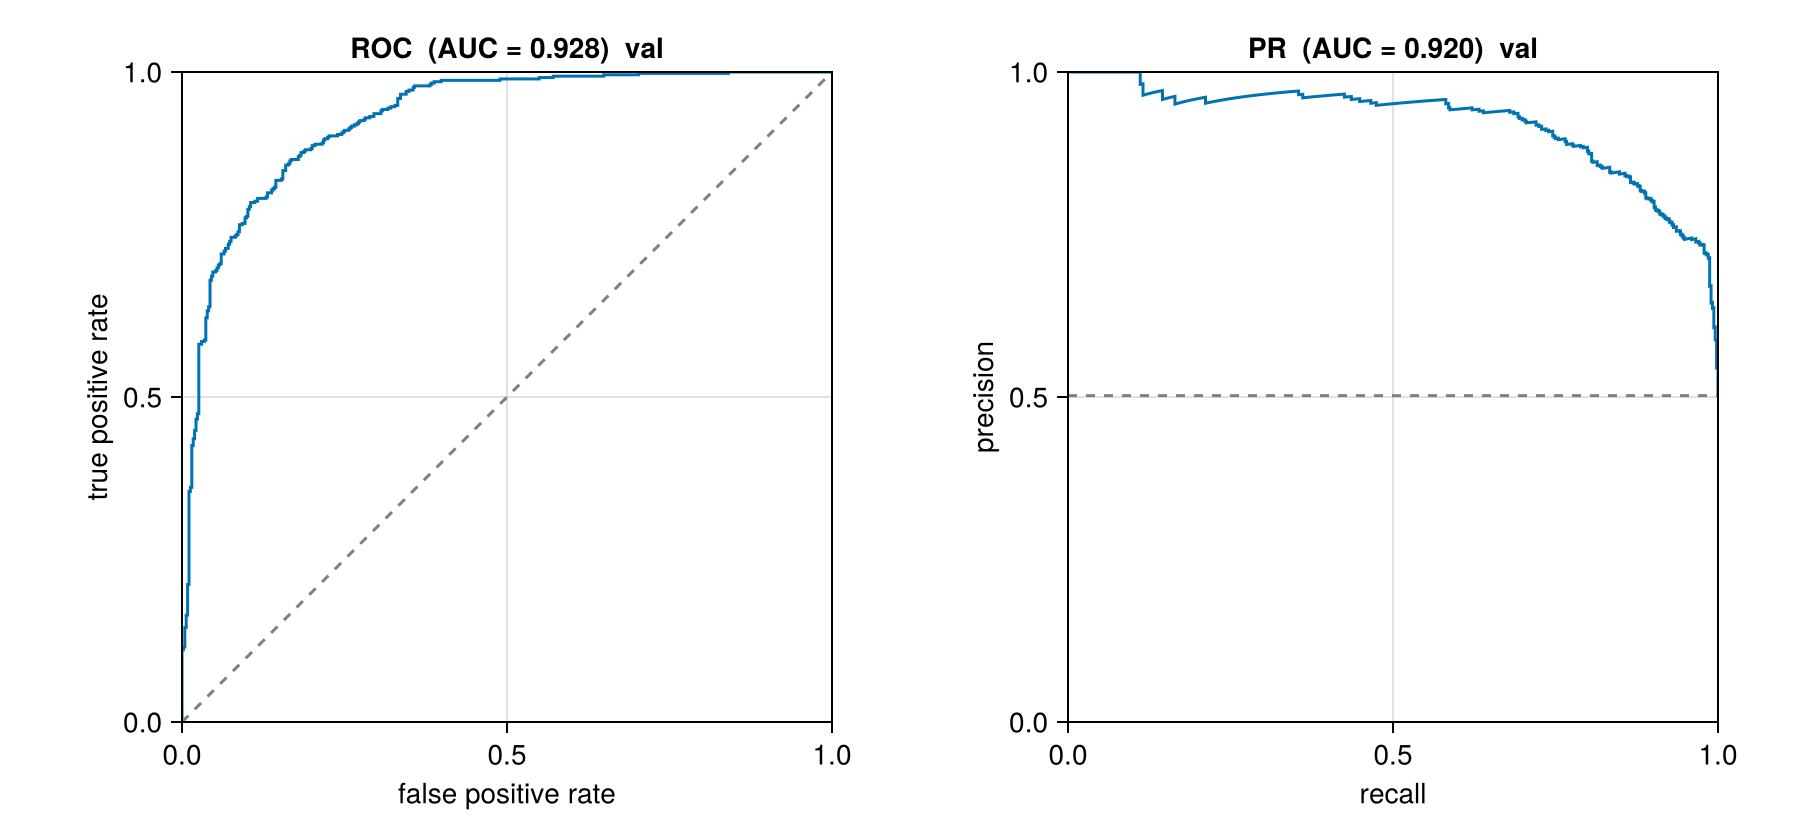

In [7]:
fig_rocpr = plot_roc_pr(val_df.label, p_val; title = "val")
savefig("exo100926_val_roc_pr.png", fig_rocpr)
fig_rocpr

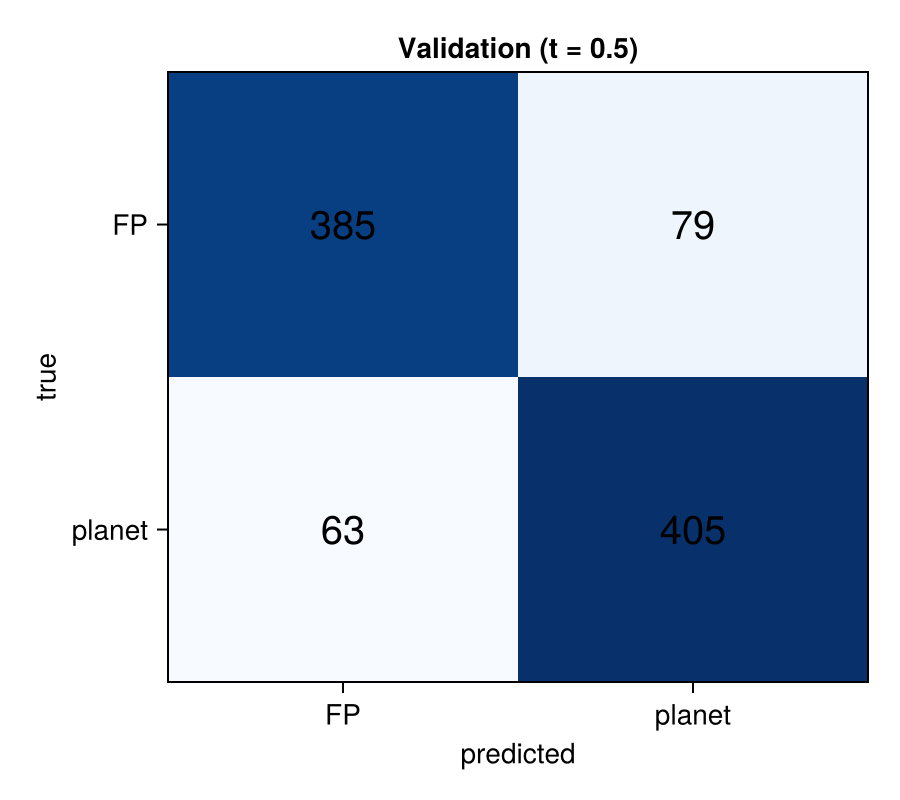

In [8]:
fig_cm = plot_confusion(val_df.label, p_val; threshold = 0.5, title = "Validation")
savefig("exo100926_val_confusion.png", fig_cm)
fig_cm

## Test set
Use the test split only once the model and its settings are frozen; tune everything on validation.

In [9]:
# p_test = predict_proba(model, data.Xte)
# evaluate_subsets(test_df, p_test)

In [10]:
# Save weights + scaler + feature list (JLD2) to models/
save_vetter("mlp_baseline_10092026.jld2", model, data;
            config = Dict("hidden" => (64, 32), "dropout" => 0.2, "lr" => 1e-3, "pos_weight" => pos_weight,
                          "seed" => 1, "split_seed" => 42, "best_epoch" => hist.best_epoch))

"c:\\JuliaProjects\\Exoplanet vetting\\models\\mlp_baseline_10092026.jld2"